# Module 3 — The Law of Large Numbers

**Probability Simulation Laboratory** · Module 3 of 8

## Learning objectives
1. define the sample mean $\bar X_n$ and explain why it is itself a random variable;
2. distinguish the main *modes of convergence* (almost sure, in probability, in $L^2$, in distribution);
3. state and prove the Weak Law via Chebyshev's inequality and state the Strong Law;
4. measure the *rate* $n^{-1/2}$ of the sampling error, and show it is the same for every finite-variance distribution;
5. see, by simulation, that the law **fails** when the mean does not exist (Cauchy).

## Research objective
Investigate how empirical averages converge towards theoretical expectations as the number of observations increases.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "03_law_of_large_numbers" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import lln                                   # 03_law_of_large_numbers/src/lln.py
SAMPLERS = lln.SAMPLERS
print(list(SAMPLERS))

['Bernoulli(0.3)', 'Uniform(0,1)', 'Exponential(1)', 'Lognormal(0,1)', 'Student t(3)', 'Cauchy']


## 1. Mathematical background

Let $X_1,X_2,\dots$ be i.i.d. with $\mathbb E X_i=\mu$ and (when it exists) $\operatorname{Var}X_i=\sigma^2$. The **sample mean** is
$\bar X_n=\frac1n\sum_{i=1}^nX_i$. It is a random variable with $\mathbb E\bar X_n=\mu$ and $\operatorname{Var}\bar X_n=\sigma^2/n$ (independence is used for the variance).

### Modes of convergence (a short map)
| Mode | Meaning of $Y_n\to Y$ | Implies |
|---|---|---|
| almost surely (a.s.) | $P(\lim_nY_n=Y)=1$ — *the sequence of numbers converges, for almost every outcome* | in probability |
| in $L^2$ | $\mathbb E|Y_n-Y|^2\to0$ | in probability |
| in probability | $\forall\varepsilon>0:\ P(|Y_n-Y|>\varepsilon)\to0$ | in distribution |
| in distribution | $F_{Y_n}(y)\to F_Y(y)$ at continuity points | — |

The converses fail in general. The Weak Law concerns convergence *in probability*; the Strong Law concerns *almost sure* convergence; the Central Limit Theorem (Module 4) concerns convergence *in distribution*.

### Weak Law of Large Numbers (finite variance version)
**Theorem.** If $X_i$ are i.i.d. with finite variance, then $\bar X_n\to\mu$ in probability (and in $L^2$).

**Proof (Chebyshev).** Chebyshev's inequality: for a random variable $Y$ with finite variance and $\varepsilon>0$, $P(|Y-\mathbb EY|\ge\varepsilon)\le\operatorname{Var}Y/\varepsilon^2$. Apply to $Y=\bar X_n$:
$$P(|\bar X_n-\mu|\ge\varepsilon)\le\frac{\sigma^2}{n\varepsilon^2}\xrightarrow[n\to\infty]{}0.\qquad\square$$
This bound is *conservative*; the CLT gives the sharper approximation $P(|\bar X_n-\mu|>\varepsilon)\approx2\{1-\Phi(\varepsilon\sqrt n/\sigma)\}$.
(Khinchin's version needs only $\mathbb E|X|<\infty$.)

### Strong Law of Large Numbers (Kolmogorov)
**Theorem.** If $X_i$ are i.i.d. with $\mathbb E|X_1|<\infty$ then $\bar X_n\to\mu$ almost surely. Conversely, if $\mathbb E|X_1|=\infty$ then $\bar X_n$ almost surely does **not** converge to a finite limit.
A.s. convergence is a statement about *whole sample paths*: each path eventually stays within $\varepsilon$ of $\mu$ forever. Equivalently $P\big(\sup_{n\ge N}|\bar X_n-\mu|>\varepsilon\big)\to0$ as $N\to\infty$ (Experiment 3.4).

### When the mean does not exist: the Cauchy distribution
For $X\sim$ Cauchy(0,1), $\mathbb E|X|=\infty$ and the characteristic function is $e^{-|t|}$. Then $\bar X_n$ has characteristic function $\big(e^{-|t|/n}\big)^n=e^{-|t|}$:
**the sample mean of $n$ Cauchy variables has exactly the same distribution as a single observation** — no averaging benefit at all.

### Sampling error
$\operatorname{SE}(\bar X_n)=\sigma/\sqrt n$. To halve the error you need four times the data. For a target absolute error $\varepsilon$ at $95\%$ confidence, $n\approx(1.96\,\sigma/\varepsilon)^2$.

## Experiment 3.1

**A. Experiment title.** Sample paths of the running mean $\bar X_k$, $k\le n$, for six distributions, with the $\pm3\sigma/\sqrt k$ envelope.

**B. Research question.** What do running means look like, and which distributions settle down?

**C. Mathematical foundation.**

For finite $\sigma$, $\bar X_k\in\mu\pm3\sigma/\sqrt k$ for most $k$ (pointwise probability $\approx99.7\%$), so paths funnel into a $k^{-1/2}$ cone around $\mu$. For Cauchy there is no $\mu$ and no cone.

**D. Theoretical prediction.**

Bernoulli, Uniform, Exponential, Lognormal and Student $t_3$ paths concentrate around their means (with the heavy-tailed ones settling more slowly and with visible jumps); Cauchy paths keep jumping at all scales.

**E. Experimental design.**

Eight independent paths of length $10{,}000$ per distribution. Theoretical means/variances are taken from the table in `lln.SAMPLERS`.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

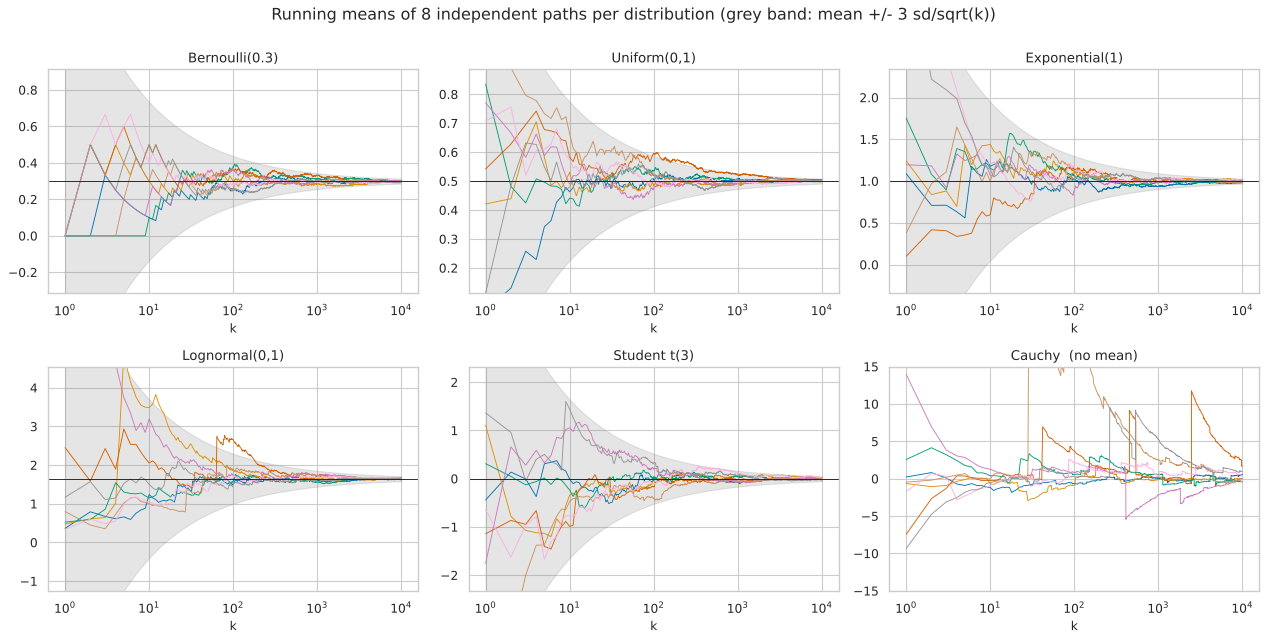

PosixPath('/home/claude/probability-simulation-laboratory/03_law_of_large_numbers/results/exp3_1_running_means.png')

In [3]:
# F. Implementation ------------------------------------------------------------------
# Xbar_k = (X_1+...+X_k)/k  ->  lln.running_mean ;  envelope  mu +/- 3 sigma / sqrt(k)
n, n_paths = 10_000, 8
k = np.arange(1, n + 1)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (name, s) in zip(axes.ravel(), SAMPLERS.items()):
    paths = lln.running_mean_paths(s, n, n_paths, rng)
    for pth in paths:
        ax.plot(k, pth, lw=0.8)
    if s.mean is not None:
        env = 3 * np.sqrt(s.var / k)
        ax.fill_between(k, s.mean - env, s.mean + env, color="grey", alpha=0.2)
        ax.axhline(s.mean, color="k", lw=0.8)
        ax.set_ylim(s.mean - 6 * np.sqrt(s.var / 20), s.mean + 6 * np.sqrt(s.var / 20))
    else:
        ax.set_ylim(-15, 15)
    ax.set(xscale="log", title=name + ("" if s.mean is not None else "  (no mean)"), xlabel="k")
fig.suptitle("Running means of 8 independent paths per distribution (grey band: mean +/- 3 sd/sqrt(k))", y=1.0)
fig.tight_layout(); save_fig(fig, RESULTS, "exp3_1_running_means.png")

**H. Theoretical versus empirical comparison.**

Five of the six panels show paths funnelling into the grey cone; the Lognormal and $t_3$ panels show occasional jumps (single large observations) that move the running mean visibly before it recovers. The Cauchy panel shows no
convergence: large jumps keep occurring at all sample sizes. (The vertical window is fixed to show the early behaviour; individual paths may leave it.)

**I. Interpretation.**

The Law of Large Numbers is a statement about *tails of the sequence*, not about early behaviour: early on, averages are noisy for every distribution. Heavy tails make single observations dominate the average (a "black swan" can move a running mean).

**J. Limitations.**

Eight paths show the typical behaviour but cannot quantify probabilities — Experiments 3.2–3.4 use thousands of replications. The $\pm3\sigma/\sqrt k$ band is pointwise, not uniform in $k$.

**K. Research conclusion.**

Finite-mean distributions show running means that settle at their mean; Cauchy running means do not settle.

**L. Further investigation.**

Plot the running *median* for the Cauchy distribution — does it converge? (It does: the sample median is consistent for the location parameter even when the mean does not exist.)

## Experiment 3.2

**A. Experiment title.** The Weak Law as a tail probability: $P(|\bar X_n-\mu|>\varepsilon)$ against Chebyshev's bound $\sigma^2/(n\varepsilon^2)$ and the CLT approximation.

**B. Research question.** How fast does $P(|\bar X_n-\mu|>\varepsilon)$ tend to zero, and how conservative is Chebyshev's bound?

**C. Mathematical foundation.**

For Bernoulli(0.3): $\mu=0.3$, $\sigma^2=0.21$, take $\varepsilon=0.05$. Chebyshev: $P\le\min\{1,\ 0.21/(n\cdot0.0025)\}=\min\{1,84/n\}$ — vacuous for $n<84$.
CLT: $P\approx2\{1-\Phi(0.05\sqrt n/\sqrt{0.21})\}$ decays like $e^{-n\varepsilon^2/(2\sigma^2)}$ — *exponentially*, far faster than the $1/n$ of Chebyshev.

**D. Theoretical prediction.**

Empirical probabilities $\le$ Chebyshev bound at every $n$; empirical $\approx$ CLT approximation; the empirical probability falls below $5\%$ around $n\approx300$ (where CLT gives $2\{1-\Phi(0.05\sqrt{300}/0.458)\}\approx0.058$ — compare the table).

**E. Experimental design.**

$n\in\{10,20,50,100,200,300,500,1000,2000\}$; $5{,}000$ independent replications read at these sample sizes from the same sequences.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,empirical,CLT approximation,Chebyshev bound,bound holds,Chebyshev / empirical
n,,,,,
10,0.7378,7.30070e-01,1.000,True,1.35538
20,0.4606,6.25585e-01,1.000,True,2.17108
50,0.4456,4.40401e-01,1.000,True,2.24417
100,0.2392,2.75234e-01,0.840,True,3.51171
200,0.1156,1.22823e-01,0.420,True,3.63322
300,0.0514,5.87817e-02,0.280,True,5.44747
500,0.0124,1.46974e-02,0.168,True,13.54839
1000,0.0008,5.59906e-04,0.084,True,105.00000
2000,0.0000,1.06355e-06,0.042,True,NaN


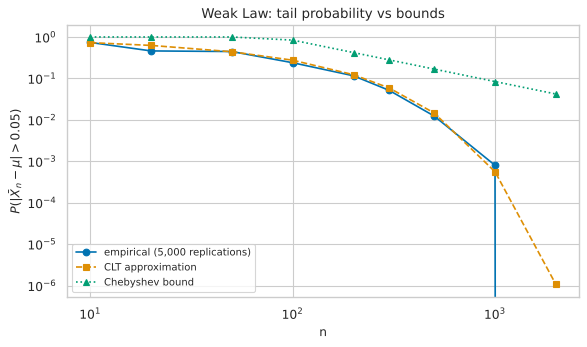

PosixPath('/home/claude/probability-simulation-laboratory/03_law_of_large_numbers/results/exp3_2_weak_law.png')

In [4]:
# F. Implementation ------------------------------------------------------------------
s = SAMPLERS["Bernoulli(0.3)"]
eps = 0.05
n_grid = np.array([10, 20, 50, 100, 200, 300, 500, 1000, 2000])
means = lln.sample_means_at(s, n_grid, reps=5000, rng=rng)          # (reps, len(n_grid)) sample means

emp = np.array([lln.exceedance_probability(means[:, j], s.mean, eps) for j in range(n_grid.size)])
cheb = np.array([lln.chebyshev_bound(s.var, int(n), eps) for n in n_grid])
clt_ = np.array([lln.clt_approximation(s.var, int(n), eps) for n in n_grid])

# G/H. Results and theory-vs-empirical comparison ----------------------------------------
wlln = pd.DataFrame({"empirical": emp, "CLT approximation": clt_, "Chebyshev bound": cheb,
                     "bound holds": emp <= cheb + 1e-12, "Chebyshev / empirical": cheb / np.where(emp > 0, emp, np.nan)},
                    index=pd.Index(n_grid, name="n"))
wlln.to_csv(RESULTS / "exp3_2_weak_law.csv")
display(wlln)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(n_grid, emp, "o-", label="empirical (5,000 replications)")
ax.plot(n_grid, clt_, "s--", label="CLT approximation")
ax.plot(n_grid, cheb, "^:", label="Chebyshev bound")
ax.set(xscale="log", yscale="log", xlabel="n", ylabel=r"$P(|\bar X_n - \mu| > 0.05)$", title="Weak Law: tail probability vs bounds")
ax.legend(); fig.tight_layout(); save_fig(fig, RESULTS, "exp3_2_weak_law.png")

**H. Theoretical versus empirical comparison.**

The empirical probability is below Chebyshev's bound at every $n$ (the `bound holds` column), and close to the CLT approximation from about $n=50$ on. At small $n$ the approximation is poorer (at $n=20$: observed $0.46$ against $0.63$) because $\bar X_n$ lives on the lattice $\{0,\tfrac1n,\dots,1\}$, so which values count as "outside $\pm\varepsilon$" changes abruptly with $n$.
The ratio Chebyshev/empirical grows with $n$ (about $3.5\times$ at $n=100$, $105\times$ at $n=1000$): the bound is valid but increasingly pessimistic, because it only uses the variance. Zeros in the empirical column at large $n$ mean *no exceedances were observed in 5,000 replications*, not that the true probability is exactly zero.

**I. Interpretation.**

Convergence in probability holds, and the tail probability decays much faster than $1/n$ when the variable is light-tailed. Chebyshev is a distribution-free guarantee — useful for proofs, wasteful for practical sample-size calculations.

**J. Limitations.**

The 5,000 replications give a floor around $1/5{,}000=2\times10^{-4}$ on the smallest probabilities that can be resolved. The comparison is for one distribution and one $\varepsilon$.

**K. Research conclusion.**

Chebyshev's bound is valid and conservative; the CLT approximation is accurate; the Weak Law (convergence in probability) is observed.

**L. Further investigation.**

Use Hoeffding's inequality for bounded variables, $P(|\bar X_n-\mu|\ge\varepsilon)\le2e^{-2n\varepsilon^2}$, and compare its tightness with Chebyshev's.

## Experiment 3.3

**A. Experiment title.** Rate of convergence of the sampling error: median absolute error $\operatorname{med}|\bar X_n-\mu|$ versus $n$ on a log-log scale, for six distributions.

**B. Research question.** Is the error rate $n^{-1/2}$ universal, and what happens for heavy tails and the Cauchy?

**C. Mathematical foundation.**

If $\bar X_n\approx\mathcal N(\mu,\sigma^2/n)$ then the median of $|\bar X_n-\mu|$ is $0.6745\,\sigma/\sqrt n$, so $\log$(median error) is linear in $\log n$ with slope $-\tfrac12$ and intercept depending on $\sigma$.
For Cauchy, $\bar X_n\overset d=X_1$, so the median absolute deviation from the centre $0$ is constant ($=1$) — slope $0$. (We use the *median* absolute error because $\mathbb E|\bar X_n-\mu|$ is infinite for Cauchy.)

**D. Theoretical prediction.**

Slope $\approx-0.5$ for Bernoulli, Uniform, Exponential, Lognormal(0,1) and $t_3$ (although finite-sample noise and slow CLT convergence may distort the heavy-tailed ones); slope $\approx0$ for Cauchy; intercepts ordered by $\sigma$.

**E. Experimental design.**

$n\in\{10,30,100,300,1000,3000,10000\}$; $1{,}000$ replications. The log-log slope is fitted by least squares. The reference centre is $\mu$ (and $0$ for Cauchy).

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,sigma,fitted_slope,predicted_median_error_at_n10000,observed_at_n10000
distribution,,,,
Bernoulli(0.3),0.45826,-0.50102,0.00309,0.00330
"Uniform(0,1)",0.28868,-0.48486,0.00195,0.00209
Exponential(1),1.00000,-0.50177,0.00675,0.00656
"Lognormal(0,1)",2.16120,-0.48242,0.01458,0.01502
Student t(3),1.73205,-0.48563,0.01168,0.01131
Cauchy,NaN,-0.00852,NaN,0.94734


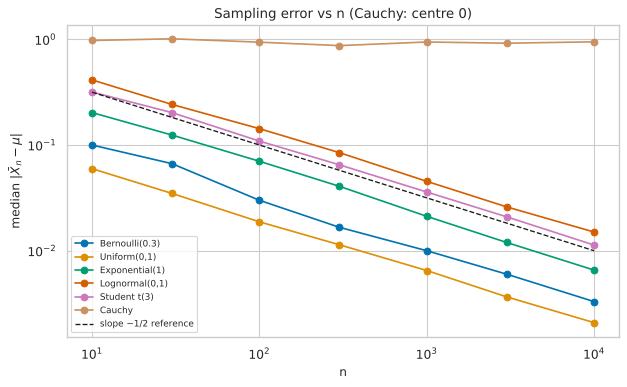

PosixPath('/home/claude/probability-simulation-laboratory/03_law_of_large_numbers/results/exp3_3_rates.png')

In [5]:
# F. Implementation ------------------------------------------------------------------
n_grid = np.array([10, 30, 100, 300, 1000, 3000, 10_000])
rows, errs = [], {}
for name, s in SAMPLERS.items():
    means = lln.sample_means_at(s, n_grid, reps=1000, rng=rng)
    centre = 0.0 if s.mean is None else s.mean
    err = np.median(np.abs(means - centre), axis=0)
    errs[name] = err
    sd = np.nan if s.var is None else np.sqrt(s.var)
    rows.append(dict(distribution=name, sigma=sd, fitted_slope=lln.loglog_slope(n_grid, err),
                     predicted_median_error_at_n10000=0.6745 * sd / 100 if s.var else np.nan, observed_at_n10000=err[-1]))
rate_table = pd.DataFrame(rows).set_index("distribution")
rate_table.to_csv(RESULTS / "exp3_3_rates.csv")
display(rate_table)

# G. Visualisation
fig, ax = plt.subplots(figsize=(8, 5))
for name, e in errs.items():
    ax.plot(n_grid, e, "o-", label=name)
ax.plot(n_grid, 1.0 / np.sqrt(n_grid), "k--", lw=1.2, label=r"slope $-1/2$ reference")
ax.set(xscale="log", yscale="log", xlabel="n", ylabel=r"median $|\bar X_n - \mu|$", title="Sampling error vs n (Cauchy: centre 0)")
ax.legend(fontsize=8); fig.tight_layout(); save_fig(fig, RESULTS, "exp3_3_rates.png")

**H. Theoretical versus empirical comparison.**

The five finite-variance distributions have fitted slopes between $-0.48$ and $-0.50$ (theory: $-0.5$), on parallel lines ordered by $\sigma$; the Cauchy slope is $-0.01$ (theory: $0$) with the curve flat near $0.95\approx1$ (the median of $|X|$ for a standard Cauchy is exactly $1$).
At $n=10{,}000$ the observed median errors agree with the Gaussian prediction $0.6745\,\sigma/\sqrt n$ to within about $5\%$ (e.g. Lognormal: $0.0150$ observed, $0.0146$ predicted; $t_3$: $0.0113$ vs $0.0117$). The small differences are Monte Carlo noise from 1,000 replications.

**I. Interpretation.**

The $n^{-1/2}$ law is *universal for finite variance*: only the constant $\sigma$ differs. This is why "one more digit of accuracy costs $100\times$ the data" holds from coin tosses to option payoffs. For the Cauchy distribution averaging gives no benefit at all — the Law of Large Numbers has an *assumption* (a finite mean), and it can fail.

**J. Limitations.**

Finite replications (1,000), fitted slope sensitive to the range of $n$ and to a few extreme replications. The Student $t_3$ has finite variance but infinite fourth moment, so the *variance* of $\bar X_n$ is known exactly but its distribution approaches the normal slowly.

**K. Research conclusion.**

Error $\propto\sigma n^{-1/2}$ for finite variance; no convergence of the sample mean for Cauchy.

**L. Further investigation.**

Repeat with the Pareto distribution $\text{Pareto}(\alpha)$ for $\alpha=1.2,\,1.5,\,2.5$ and fit the slope: for $1<\alpha<2$ the mean exists (the Law holds) but the variance is infinite, and the rate is slower than $n^{-1/2}$ (slope $1/\alpha-1$).

## Experiment 3.4

**A. Experiment title.** The Strong Law as a statement about sample paths: $P\big(\sup_{n\ge N}|\bar X_n-\mu|>\varepsilon\big)$ versus the Weak-Law quantity $P(|\bar X_N-\mu|>\varepsilon)$.

**B. Research question.** What is the difference, in simulation, between convergence in probability and almost-sure convergence?

**C. Mathematical foundation.**

Almost sure convergence $\bar X_n\to\mu$ means $\sup_{n\ge N}|\bar X_n-\mu|\to0$ as $N\to\infty$ for almost every path, i.e. for every $\varepsilon$, $P\big(\sup_{n\ge N}|\bar X_n-\mu|>\varepsilon\big)\to0$.
Convergence in probability only controls $P(|\bar X_N-\mu|>\varepsilon)$ at a *single* $N$. Clearly $P(\sup_{n\ge N}\cdots)\ge P(|\bar X_N-\mu|>\varepsilon)$.

**D. Theoretical prediction.**

Both probabilities decrease to $0$ in $N$ (the Strong Law, which is stronger, holds for Bernoulli(0.3)); the supremum version is larger than the single-$N$ version, by a factor that is modest here.

**E. Experimental design.**

Bernoulli(0.3), $\varepsilon=0.02$; $600$ paths of length $20{,}000$; for $N\in\{10,100,1000,5000\}$ record the fraction of paths whose running mean ever leaves $[\mu-\varepsilon,\mu+\varepsilon]$ for some $n\in[N,20{,}000]$. (The truncation at $20{,}000$ makes the supremum a lower bound on the true infinite-horizon value.)

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,P_outside_at_N,P_outside_for_some_n_ge_N
N,,
10,0.76167,1.00000
100,0.66833,0.99667
1000,0.16667,0.32167
5000,0.00333,0.00833


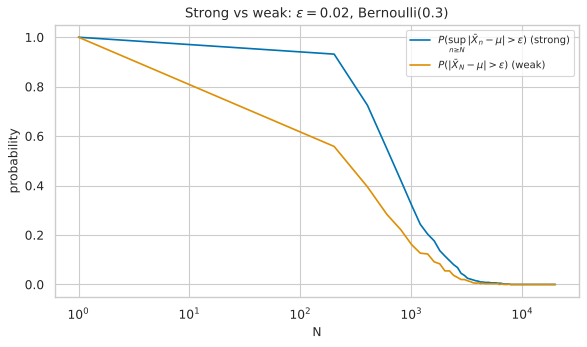

PosixPath('/home/claude/probability-simulation-laboratory/03_law_of_large_numbers/results/exp3_4_strong_vs_weak.png')

In [6]:
# F. Implementation ------------------------------------------------------------------
s = SAMPLERS["Bernoulli(0.3)"]
eps, n_max, n_paths = 0.02, 20_000, 600
paths = lln.running_mean_paths(s, n_max, n_paths, rng)           # (600, 20000) array of running means
dev = np.abs(paths - s.mean) > eps                               # True where the path is outside the band

rows = []
for N in [10, 100, 1000, 5000]:
    sup_prob = dev[:, N - 1:].any(axis=1).mean()                 # ever outside for some n >= N (up to n_max)
    single_prob = dev[:, N - 1].mean()                           # outside at exactly n = N
    rows.append(dict(N=N, P_outside_at_N=single_prob, P_outside_for_some_n_ge_N=sup_prob))
strong = pd.DataFrame(rows).set_index("N")
strong.to_csv(RESULTS / "exp3_4_strong_law.csv")
display(strong)

# One picture: the set of paths that are still 'bad' after N
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bad_after = np.array([dev[:, N - 1:].any(axis=1).mean() for N in range(1, n_max + 1, 200)])
single = np.array([dev[:, N - 1].mean() for N in range(1, n_max + 1, 200)])
Ns = np.arange(1, n_max + 1, 200)
ax.plot(Ns, bad_after, label=r"$P(\sup_{n\geq N}|\bar X_n-\mu|>\varepsilon)$ (strong)")
ax.plot(Ns, single, label=r"$P(|\bar X_N-\mu|>\varepsilon)$ (weak)")
ax.set(xscale="log", xlabel="N", ylabel="probability", title=r"Strong vs weak: $\varepsilon=0.02$, Bernoulli(0.3)")
ax.legend(); fig.tight_layout(); save_fig(fig, RESULTS, "exp3_4_strong_vs_weak.png")

**H. Theoretical versus empirical comparison.**

In the table the "for some $n\ge N$" column is at least as large as the single-$N$ column at every $N$ and both tend to zero, as predicted: for example at $N=1000$ the probabilities are about $0.17$ (single) and $0.32$ (supremum), and at $N=5000$ about $0.003$ and $0.008$. For small $N$ both are close to $1$ because $\varepsilon=0.02$ is far smaller than the standard error $\sigma/\sqrt n\approx0.046$ at $n=100$. Values at large $N$ are estimated from only 600 paths, so
small probabilities are resolved only to about $\pm0.01$.

**I. Interpretation.**

The Weak Law says that at any *given* large $n$ the average is probably close to $\mu$; the Strong Law says that, with probability one, the average *eventually stays* close. For practical estimation these differ little, but the distinction matters in
theory (e.g. proving that Monte Carlo estimators converge along a single long run — the typical use case).

**J. Limitations.**

Simulation cannot verify an almost-sure statement: we only see finite paths ($n\le20{,}000$), and a probability-one event cannot be distinguished from one with probability $0.9999$.

**K. Research conclusion.**

Sample-path behaviour is consistent with almost-sure convergence for Bernoulli averages; the supremum over the tail is strictly harder to control than the value at a single $N$.

**L. Further investigation.**

Use the Law of the Iterated Logarithm, $\limsup\frac{\bar X_n-\mu}{\sigma\sqrt{2\ln\ln n/n}}=1$ a.s., to describe the *exact* size of the largest excursions, and compare with simulation.

## Experiment 3.5

**A. Experiment title.** Sample-size planning: $n\approx(z_{0.975}\sigma/\varepsilon)^2$ achieves absolute error $\le\varepsilon$ with probability $\approx0.95$.

**B. Research question.** How many observations are needed for a target accuracy, and does the formula hold in simulation?

**C. Mathematical foundation.**

By the CLT, $P(|\bar X_n-\mu|\le\varepsilon)\approx2\Phi(\varepsilon\sqrt n/\sigma)-1$. Setting this to $0.95$ gives $\varepsilon\sqrt n/\sigma=1.96$, so $n=(1.96\sigma/\varepsilon)^2$.
For Bernoulli(0.3), $\varepsilon=0.01$: $n=3.8416\times0.21/10^{-4}\approx8{,}067$. For Uniform(0,1) with $\varepsilon=0.01$: $n=3.8416\times\frac1{12}/10^{-4}\approx3{,}201$.

**D. Theoretical prediction.**

With the planned $n$, about $95\%$ of replications satisfy $|\bar X_n-\mu|\le\varepsilon$.

**E. Experimental design.**

For each of the two distributions, simulate $20{,}000$ means at the planned $n$ and compute the fraction within $\varepsilon$ (with a Wilson interval).

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

In [7]:
# F/G/H. Implementation, results, comparison -----------------------------------------------
z = stats.norm.ppf(0.975)
eps = 0.01
rows = []
for name in ["Bernoulli(0.3)", "Uniform(0,1)"]:
    s = SAMPLERS[name]
    n_plan = int(np.ceil((z * np.sqrt(s.var) / eps) ** 2))
    m = lln.sample_means_at(s, [n_plan], reps=20_000, rng=rng)[:, 0]
    k = int((np.abs(m - s.mean) <= eps).sum())
    lo, hi = wilson_interval(k, 20_000)
    rows.append(dict(distribution=name, planned_n=n_plan, coverage=k / 20_000, wilson_low=lo, wilson_high=hi))
plan = pd.DataFrame(rows).set_index("distribution")
plan.to_csv(RESULTS / "exp3_5_sample_size.csv")
display(plan)

,planned_n,coverage,wilson_low,wilson_high
distribution,,,,
Bernoulli(0.3),8068,0.95135,0.94828,0.95425
"Uniform(0,1)",3202,0.95055,0.94746,0.95347


**H. Theoretical versus empirical comparison.**

Both empirical proportions are close to $0.95$ (the Bernoulli's discreteness can shift it by a fraction of a percentage point). The Wilson intervals show whether the planned $n$ delivers the intended confidence.

**I. Interpretation.**

The formula needs $\sigma$ — in practice unknown, estimated from a pilot sample or bounded (for Bernoulli, $\sigma^2\le\tfrac14$ gives the conservative $n\le(0.98/\varepsilon)^2$).

**J. Limitations.**

CLT approximation; the sample size for *relative* error or for heavy-tailed variables needs different treatment.

**K. Research conclusion.**

The Law of Large Numbers plus the CLT gives a practical rule for choosing $n$, verified by simulation.

**L. Further investigation.**

In Module 5 use the same calculation to decide how many Monte Carlo paths are needed to price an option to the nearest cent.

## Exercises (paper first)

1. Prove Chebyshev's inequality from Markov's inequality $P(Y\ge a)\le\mathbb E Y/a$ for $Y\ge0$.
2. Show $\operatorname{Var}\bar X_n=\sigma^2/n$ and state which assumption you used. What changes if $\operatorname{Corr}(X_i,X_j)=\rho>0$ for all $i\ne j$? (Hint: the variance no longer tends to $0$.)
3. For Bernoulli($p$), find the smallest $n$ guaranteed by Chebyshev to give $P(|\bar X_n-p|\ge0.05)\le0.05$ for *every* $p$, and compare with the CLT-based $n$ at $p=\tfrac12$.
4. Show with characteristic functions that the mean of $n$ i.i.d. Cauchy variables is Cauchy. Why does that contradict no law?
5. Give an example (a sequence $Y_n$) that converges in probability but not almost surely. (Hint: "typewriter" indicator sequence.)
6. For Pareto with tail index $\alpha\in(1,2)$ explain why the mean exists, the variance does not, and the sampling error decays more slowly than $n^{-1/2}$.
7. A trading strategy's daily returns have mean $0.05\%$ and sd $1\%$. How many days of i.i.d. data are needed before the standard error of the mean is a quarter of the mean? Comment on what this implies about estimating expected returns.

## Summary of Module 3
* $\bar X_n\to\mu$ in probability (weak) and almost surely (strong) when $\mathbb E|X|<\infty$.
* The error is $\sigma/\sqrt n$ — universal for finite variance; Chebyshev is valid but conservative.
* The Cauchy distribution shows the law needs a finite mean.
* Simulation illustrates convergence but cannot prove it.

**Next:** Module 4 — the Central Limit Theorem.